## In Multiclass Classification the number of outputs is equal to the number of classes
### eg. In MNIST Dataset with 0-9 digits we will have 10 nodes each representing one-digit

# (28*28) 784 i/p nodes ---> 128 nodes in hidden layer ---> 10 o/p nodes

In [1]:
import tensorflow 
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten

In [2]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

In [3]:
# X_train
# X_test

In [4]:
print(X_train.shape)
print(X_test.shape)

(60000, 28, 28)
(10000, 28, 28)


In [5]:
print(y_train.shape)
print(y_test.shape)

(60000,)
(10000,)


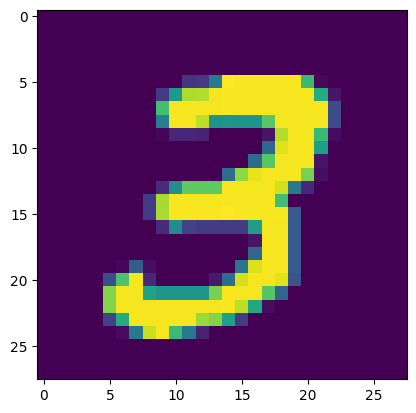

In [6]:
import matplotlib.pyplot as plt
plt.imshow(X_train[7])

In [7]:
X_train = X_train / 255.0 
X_test = X_test / 255.0
# When you do this, you are normalizing the pixel values of the images in the MNIST dataset. 
# The original pixel values range from 0 to 255, and by dividing by 255.0, you scale them down to a range of 0 to 1. 
# This normalization is important for training neural networks, as it helps improve convergence and stability during the training process. (Scaling)

In [8]:
print('X_train:', X_train, '\n\n\n\n')
print('X_test:', X_test)

X_train: [[[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]

 [[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]

 [[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]

 ...

 [[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]

 [[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]

 [[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]] 


In [9]:
model = Sequential()

model.add(Flatten(input_shape=(28, 28)))
model.add(Dense(128, activation='relu'))
model.add(Dense(64, activation='relu'))
model.add(Dense(10, activation='softmax')) # More than 2 classes, so we use softmax activation function 
# and if 1 class, we use sigmoid activation function

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy']) 
# In sparse_categorical_crossentropy, the labels are provided as integers (sparse format) so no need of OHE!


In [12]:
history = model.fit(X_train, y_train, epochs=10, validation_split=0.2)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9211 - loss: 0.2719 - val_accuracy: 0.9608 - val_loss: 0.1323
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9659 - loss: 0.1143 - val_accuracy: 0.9684 - val_loss: 0.1043
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9771 - loss: 0.0769 - val_accuracy: 0.9726 - val_loss: 0.0931
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9811 - loss: 0.0602 - val_accuracy: 0.9749 - val_loss: 0.0887
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9858 - loss: 0.0468 - val_accuracy: 0.9718 - val_loss: 0.0965
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9880 - loss: 0.0373 - val_accuracy: 0.9736 - val_loss: 0.0998
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9900 - loss: 0.0317 - val_accuracy: 0.9745 - val_loss: 0.0985
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9913 - loss: 0.0257 -

In [13]:
y_prob = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [14]:
y_pred =y_prob.argmax(axis=1)

In [15]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
accuracy_score(y_test, y_pred)

0.9763

In [16]:
confusion_matrix(y_test, y_pred)

array([[ 972,    1,    1,    0,    0,    1,    3,    1,    1,    0],
       [   0, 1117,    2,    2,    0,    1,    3,    2,    7,    1],
       [   3,    1, 1004,    4,    1,    0,    1,    9,    5,    4],
       [   4,    0,    2,  977,    0,   11,    0,    5,    4,    7],
       [   3,    0,    1,    0,  947,    2,    6,    1,    2,   20],
       [   5,    0,    0,    1,    1,  873,    4,    0,    7,    1],
       [   5,    2,    0,    2,    2,    3,  940,    0,    4,    0],
       [   1,    1,    4,    3,    2,    0,    0, 1009,    5,    3],
       [  11,    0,    0,    2,    1,    1,    4,    5,  948,    2],
       [   5,    2,    0,    2,    5,    5,    0,   11,    3,  976]])

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.96      0.99      0.98       980
           1       0.99      0.98      0.99      1135
           2       0.99      0.97      0.98      1032
           3       0.98      0.97      0.98      1010
           4       0.99      0.96      0.98       982
           5       0.97      0.98      0.98       892
           6       0.98      0.98      0.98       958
           7       0.97      0.98      0.97      1028
           8       0.96      0.97      0.97       974
           9       0.96      0.97      0.96      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



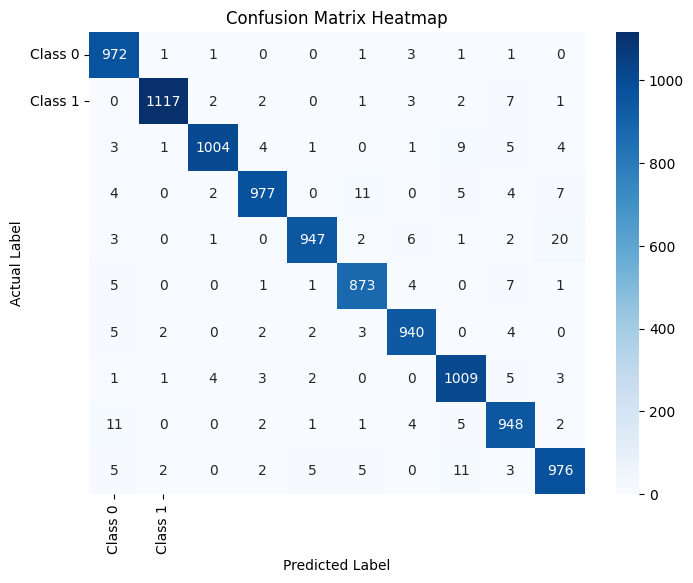

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# 1. Get the raw confusion matrix
cm = confusion_matrix(y_test, y_pred)

# =========================================================
# MORE DATA: Classification Report
# This gives you Precision, Recall, F1-Score, and Accuracy
# =========================================================
print("=== Classification Report ===")
print(classification_report(y_test, y_pred))

# =========================================================
# VISUALIZATION Option 1: Clean & Professional (Seaborn Heatmap)
# Great for custom styling and percentages
# =========================================================
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Class 0', 'Class 1'], # Change to your actual class names
            yticklabels=['Class 0', 'Class 1'])
plt.title('Confusion Matrix Heatmap')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

# =========================================================
# VISUALIZATION Option 2: Scikit-learn Built-in (Quickest)
# =========================================================
# disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Class 0', 'Class 1'])
# disp.plot(cmap='Blues')
# plt.show()


In [18]:
classification_report(y_test, y_pred,)

'              precision    recall  f1-score   support\n\n           0       0.96      0.99      0.98       980\n           1       0.99      0.98      0.99      1135\n           2       0.99      0.97      0.98      1032\n           3       0.98      0.97      0.98      1010\n           4       0.99      0.96      0.98       982\n           5       0.97      0.98      0.98       892\n           6       0.98      0.98      0.98       958\n           7       0.97      0.98      0.97      1028\n           8       0.96      0.97      0.97       974\n           9       0.96      0.97      0.96      1009\n\n    accuracy                           0.98     10000\n   macro avg       0.98      0.98      0.98     10000\nweighted avg       0.98      0.98      0.98     10000\n'

=== Structured Metrics Table ===
              precision    recall  f1-score
0              0.963330  0.991837  0.977376
1              0.993772  0.984141  0.988933
2              0.990138  0.972868  0.981427
3              0.983887  0.967327  0.975537
4              0.987487  0.964358  0.975786
5              0.973244  0.978700  0.975964
6              0.978148  0.981211  0.979677
7              0.967402  0.981518  0.974408
8              0.961460  0.973306  0.967347
9              0.962525  0.967294  0.964904
accuracy       0.976300  0.976300  0.976300
macro avg      0.976139  0.976256  0.976136
weighted avg   0.976459  0.976300  0.976318


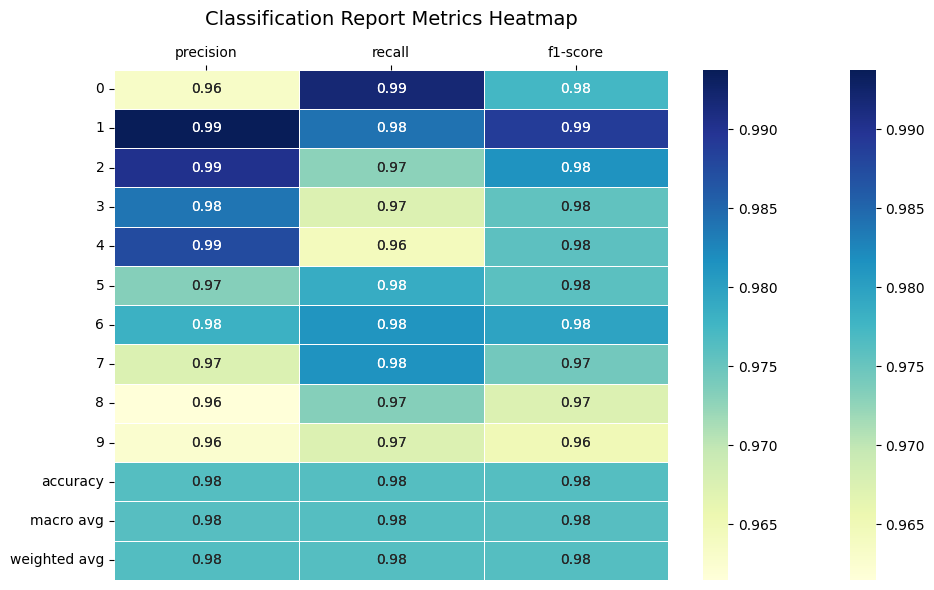

In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# 1. Generate the report as a dictionary (crucial for converting to a DataFrame)
report_dict = classification_report(y_test, y_pred, output_dict=True)

# 2. Convert to a Pandas DataFrame and clean it up for plotting
# We drop 'support' from the heatmap because its scale is much larger than 0.0 - 1.0
df_report = pd.DataFrame(report_dict).iloc[:-1, :].T 

# =========================================================
# MORE DATA: View the structured table
# =========================================================
print("=== Structured Metrics Table ===")
print(df_report)

# =========================================================
# VISUALIZATION: Heatmap of the metrics
# =========================================================
plt.figure(figsize=(10, 6))
# Using a color map where higher scores look "better" (e.g., 'YlGnBu' or 'RdYlGn')
sns.heatmap(df_report[['precision', 'recall', 'f1-score']], 
            annot=True, 
            cmap='YlGnBu', 
            fmt='.2f', 
            linewidths=0.5)
# 1. Assign to 'ax'
ax = sns.heatmap(df_report[['precision', 'recall', 'f1-score']], 
                 annot=True, cmap='YlGnBu', fmt='.2f', linewidths=0.5)

plt.title('Classification Report Metrics Heatmap', fontsize=14, pad=15)

# 2. Call tick_top() directly on the axes object
ax.xaxis.tick_top() 

plt.tight_layout()
plt.show()



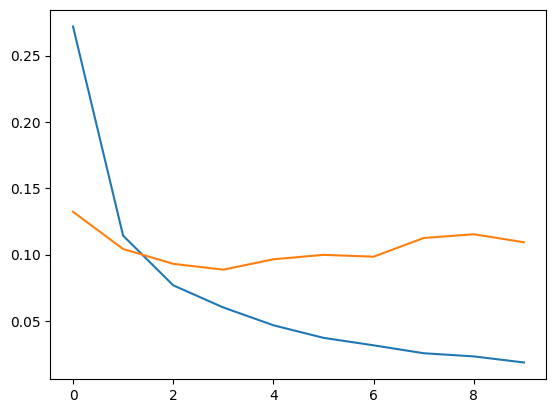

In [20]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

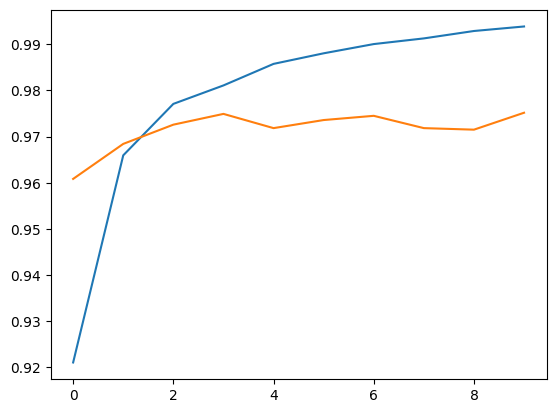

In [21]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])